# KDD | Where do Formula 1 drivers gain grid places?

Discover which circuits and starting positions are associated with gaining places among drivers who finish, then check whether the patterns persist.

[Dataset on Kaggle](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020)

Use a standard CPU runtime and run the cells in order.

Methodology reference: [Fayyad, Piatetsky-Shapiro, and Smyth, 1996](https://onlinelibrary.wiley.com/doi/abs/10.1609/aimag.v17i3.1230). Kaggle snapshot version: 24.

## Setup

Download the Kaggle archive, check the selected CSVs against their SHA-256 fingerprints, and report the package versions. The fingerprints protect the analysis against changes to the source files.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from importlib.metadata import version

KAGGLE_DATASET = 'rohanrao/formula-1-world-championship-1950-2020'
KAGGLE_VERSION = 24
EXPECTED_SHA256 = {'results.csv': 'a2392658044286800a0a946138067d9823f39e59147eeef0cbdda858ff172441', 'races.csv': '4839d035abc603fa88fa08fa976a86d76cff35f3e94cb767d25f735a5a3376ef', 'circuits.csv': '8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b0213e7a38b3a5c3cba6eb', 'status.csv': 'c36b1287f2421a288c38b0ce875d6ed04ff26bbda3e06db3d99e12197ea894aa'}
ARTIFACTS = Path(os.environ.get("PROJECT_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)


def load_kaggle_tables():
    archive_path = os.environ.get("PROJECT_DATA_ZIP")
    if archive_path:
        archive = Path(archive_path).read_bytes()
    else:
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}?datasetVersionNumber={KAGGLE_VERSION}"
        with urlopen(Request(url, headers={"User-Agent": "CMPE255-notebook/1.0"}), timeout=120) as response:
            archive = response.read()
    tables = {}
    with ZipFile(BytesIO(archive)) as zipped:
        for filename, expected in EXPECTED_SHA256.items():
            content = zipped.read(filename)
            actual = hashlib.sha256(content).hexdigest()
            if actual != expected:
                raise ValueError(f"{filename} changed. Use the archived Kaggle version described in the README.")
            tables[filename] = pd.read_csv(BytesIO(content), na_values=[r"\N"])
    return tables


def save_json(filename, payload):
    (ARTIFACTS / filename).write_text(json.dumps(payload, indent=2) + "\n")


tables = load_kaggle_tables()
print("Python", sys.version.split()[0])
print({name: version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})
print({name: df.shape for name, df in tables.items()})
print("Kaggle snapshot:", KAGGLE_VERSION)

Python 3.14.7
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
{'results.csv': (26759, 18), 'races.csv': (1125, 18), 'circuits.csv': (77, 9), 'status.csv': (139, 2)}
Kaggle snapshot: 24


## 1. Selection

Use results for grid and finish positions, races for season and circuit keys, circuits for names, and status for result labels. One result row represents one driver in one race. Select the 2014–2023 Grands Prix. Treat 2014–2021 as discovery years and reserve 2022–2023 for evaluation.

In [2]:
results = tables["results.csv"]
races = tables["races.csv"][["raceId", "circuitId", "year"]]
circuits = tables["circuits.csv"][["circuitId", "name"]].rename(columns={"name": "circuit"})
statuses = tables["status.csv"][["statusId", "status"]]
preview_columns = ["raceId", "driverId", "grid", "position", "positionOrder", "statusId"]
display(results[preview_columns].head())

,raceId,driverId,grid,position,positionOrder,statusId
0,18,1,1,1.0,1,1
1,18,2,5,2.0,2,1
2,18,3,7,3.0,3,1
3,18,4,11,4.0,4,1
4,18,5,3,5.0,5,1


## 2. Preprocessing

Join each result to one race, one circuit, and one status. A zero grid value identifies a record without a numbered starting position. Report those records as a separate group. Use the Finished and +N Lap status labels as a completion rule. Keep retirement and other statuses outside the primary places-gained analysis and report their count.

In [3]:
entries = (results.merge(races, on="raceId", validate="many_to_one")
           .merge(circuits, on="circuitId", validate="many_to_one")
           .merge(statuses, on="statusId", validate="many_to_one"))
entries = entries.loc[entries.year.between(2014, 2023)].copy()
assert not entries.duplicated(["raceId", "driverId"]).any()
entries["completed"] = entries.status.str.fullmatch(r"Finished|\+\d+ Laps?", na=False)
entries["finish"] = pd.to_numeric(entries.position, errors="coerce")
entries["eligible"] = entries.completed & entries.grid.gt(0) & entries.finish.notna()
scope = {
    "total_driver_entries": len(entries),
    "no_numbered_grid_position": int(entries.grid.eq(0).sum()),
    "other_finish_status": int((~entries.completed).sum()),
    "eligible": int(entries.eligible.sum()),
}
display(pd.Series(scope))

total_driver_entries         4147
no_numbered_grid_position      68
other_finish_status           747
eligible                     3352
dtype: int64

Check the keys and year coverage. A merge with missing keys could otherwise remove rows silently.

In [4]:
assert results.raceId.isin(races.raceId).all()
assert races.circuitId.isin(circuits.circuitId).all()
assert results.statusId.isin(statuses.statusId).all()
coverage = entries.groupby("year").agg(races=("raceId", "nunique"), entries=("driverId", "size"), eligible=("eligible", "sum"))
display(coverage)

,races,entries,eligible
year,,,
2014,19,407,320
2015,19,378,296
2016,21,462,378
2017,20,400,305
2018,21,420,335
2019,21,420,349
2020,17,340,279
2021,22,440,372
2022,22,440,357


## 3. Transformation

Places gained equals starting grid position minus finishing position. A positive value means the driver finished ahead of their starting position. Group comparable starting positions into four bands. A driver who starts first cannot gain a place, so comparisons across circuits use the same grid band.

In [5]:
drivers = entries.loc[entries.eligible].copy()
drivers["places_gained"] = drivers.grid - drivers.finish
drivers["gained"] = drivers.places_gained.gt(0)
drivers["grid_band"] = pd.cut(drivers.grid, [0, 5, 10, 15, np.inf], labels=["1–5", "6–10", "11–15", "16+"], right=True)
display(drivers[["year", "circuit", "grid", "finish", "places_gained", "grid_band"]].head(8))

,year,circuit,grid,finish,places_gained,grid_band
22127,2014,Albert Park Grand Prix Circuit,3,1.0,2.0,1–5
22128,2014,Albert Park Grand Prix Circuit,4,2.0,2.0,1–5
22129,2014,Albert Park Grand Prix Circuit,10,3.0,7.0,6–10
22130,2014,Albert Park Grand Prix Circuit,5,4.0,1.0,1–5
22131,2014,Albert Park Grand Prix Circuit,15,5.0,10.0,11–15
22132,2014,Albert Park Grand Prix Circuit,7,6.0,1.0,6–10
22133,2014,Albert Park Grand Prix Circuit,11,7.0,4.0,11–15
22134,2014,Albert Park Grand Prix Circuit,6,8.0,-2.0,6–10


In [6]:
trace_row = drivers.loc[drivers.gained].iloc[0]
assert trace_row.places_gained == trace_row.grid - trace_row.finish
display(trace_row[["circuit", "grid", "finish", "places_gained", "grid_band"]])
print("Grid-zero and other finish-status counts can overlap.")

circuit          Albert Park Grand Prix Circuit
grid                                          3
finish                                      1.0
places_gained                               2.0
grid_band                                   1–5
Name: 22127, dtype: object

Grid-zero and other finish-status counts can overlap.


## 4. Data mining

Discover circuit and starting-grid groups with a high share of drivers who gained places. Keep groups with at least 20 discovery entries. Rank each group by how far its gain rate exceeds the pooled rate for the same starting band. The pooled rate includes the group. Keep the top five before reading the later-season results.

In [7]:
def group_summary(frame):
    return frame.groupby(["circuit", "grid_band"], observed=True).agg(
        entries=("gained", "size"),
        gain_rate=("gained", "mean"),
        average_places=("places_gained", "mean"),
    )


discovery = drivers.loc[drivers.year.le(2021)]
later = drivers.loc[drivers.year.ge(2022)]
discovery_bands = discovery.groupby("grid_band", observed=True).gained.mean().rename("band_rate")
patterns = group_summary(discovery).join(discovery_bands, on="grid_band")
patterns["lift"] = patterns.gain_rate - patterns.band_rate
top_patterns = patterns.loc[patterns.entries.ge(20)].sort_values("lift", ascending=False).head(5)
display(top_patterns.round(3))

entries  gain_rate  average_places  \
circuit                       grid_band                                       
Bahrain International Circuit 1–5             38      0.474          -0.553   
Marina Bay Street Circuit     11–15           21      0.810           3.286   
Circuit of the Americas       6–10            24      0.625           0.417   
                              11–15           26      0.808           2.231   
Autódromo Hermanos Rodríguez  6–10            26      0.615           0.385   

                                         band_rate   lift  
circuit                       grid_band                    
Bahrain International Circuit 1–5            0.263  0.211  
Marina Bay Street Circuit     11–15          0.657  0.152  
Circuit of the Americas       6–10           0.474  0.151  
                              11–15          0.657  0.150  
Autódromo Hermanos Rodríguez  6–10           0.474  0.141

## 5. Interpretation and evaluation

Check the same five groups in 2022–2023. Label a group inconclusive when it has fewer than 10 later entries. For groups with enough entries, report whether their gain rate remains above the later pooled rate for the same starting band. This comparison describes associations among finishers. It cannot tell us whether the circuit caused a driver to gain places.

In [8]:
later_bands = later.groupby("grid_band", observed=True).gained.mean().rename("band_rate")
later_summary = group_summary(later).join(later_bands, on="grid_band")
comparison = top_patterns.add_prefix("discovery_").join(later_summary.add_prefix("later_"))
comparison["later_entries"] = comparison.later_entries.fillna(0).astype(int)
comparison["later_lift"] = comparison.later_gain_rate - comparison.later_band_rate
comparison["assessment"] = np.select(
    [comparison.later_entries.lt(10), comparison.later_lift.gt(0)],
    ["Inconclusive", "Still above band rate"],
    default="Did not stay above band rate",
)
display(comparison.round(3))

discovery_entries  \
circuit                       grid_band                      
Bahrain International Circuit 1–5                       38   
Marina Bay Street Circuit     11–15                     21   
Circuit of the Americas       6–10                      24   
                              11–15                     26   
Autódromo Hermanos Rodríguez  6–10                      26   

                                         discovery_gain_rate  \
circuit                       grid_band                        
Bahrain International Circuit 1–5                      0.474   
Marina Bay Street Circuit     11–15                    0.810   
Circuit of the Americas       6–10                     0.625   
                              11–15                    0.808   
Autódromo Hermanos Rodríguez  6–10                     0.615   

                                         discovery_average_places  \
circuit                       grid_band                             
Bahrain International Circuit 1–5                          -0.553   
Marina Bay Street Circuit     11–15                         3.286   
Circuit of the Americas       6–10                          0.417   
                              11–15                         2.231   
Autódromo Hermanos Rodríguez  6–10                          0.385   

                                         discovery_band_rate  discovery_lift  \
circuit                       grid_band                                        
Bahrain International Circuit 1–5                      0.263           0.211   
Marina Bay Street Circuit     11–15                    0.657           0.152   
Circuit of the Americas       6–10                     0.474           0.151   
                              11–15                    0.657           0.150   
Autódromo Hermanos Rodríguez  6–10                     0.474           0.141   

                                         later_entries  later_gain_rate  \
circuit                       grid_band                                   
Bahrain International Circuit 1–5                    7            0.429   
Marina Bay Street Circuit     11–15                  8            0.875   
Circuit of the Americas       6–10                   7            0.714   
                              11–15                 10            0.600   
Autódromo Hermanos Rodríguez  6–10                   9            0.444   

                                         later_average_places  \
circuit                       grid_band                         
Bahrain International Circuit 1–5                       0.714   
Marina Bay Street Circuit     11–15                     4.125   
Circuit of the Americas       6–10                      1.857   
                              11–15                     2.400   
Autódromo Hermanos Rodríguez  6–10                     -0.778   

                                         later_band_rate  later_lift  \
circuit                       grid_band                                
Bahrain International Circuit 1–5                  0.274       0.155   
Marina Bay Street Circuit     11–15                0.627       0.248   
Circuit of the Americas       6–10                 0.484       0.230   
                              11–15                0.627      -0.027   
Autódromo Hermanos Rodríguez  6–10                 0.484      -0.039   

                                                           assessment  
circuit                       grid_band                                
Bahrain International Circuit 1–5                        Inconclusive  
Marina Bay Street Circuit     11–15                      Inconclusive  
Circuit of the Americas       6–10                       Inconclusive  
                              11–15      Did not stay above band rate  
Autódromo Hermanos Rodríguez  6–10                       Inconclusive

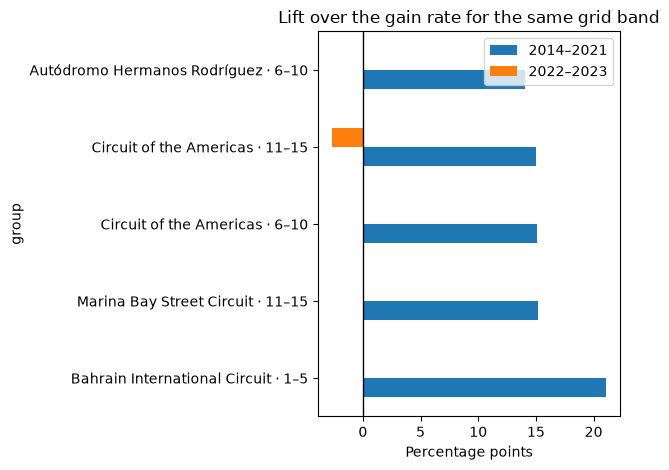

In [9]:
plot_data = comparison.reset_index()
plot_data["group"] = plot_data.circuit.astype(str) + " · " + plot_data.grid_band.astype(str)
plot_data["later_plot_lift"] = plot_data.later_lift.where(plot_data.later_entries.ge(10))
ax = plot_data.set_index("group")[["discovery_lift", "later_plot_lift"]].rename(
    columns={"discovery_lift": "2014–2021", "later_plot_lift": "2022–2023"}
).mul(100).plot.barh(title="Lift over the gain rate for the same grid band", xlabel="Percentage points")
ax.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()
comparison.to_csv(ARTIFACTS / "pattern_comparison.csv")
save_json("scope.json", scope)

Entries from the same Grand Prix share race conditions. Count distinct races behind each later result. Use this as a second measure of how much evidence each group has.

In [10]:
later_events = later.groupby(["circuit", "grid_band"], observed=True).raceId.nunique()
later_support = comparison[["later_entries", "later_gain_rate", "assessment"]].join(later_events.rename("later_races"))
display(later_support.round(3))
later_support.to_csv(ARTIFACTS / "later_race_support.csv")

later_entries  later_gain_rate  \
circuit                       grid_band                                   
Bahrain International Circuit 1–5                    7            0.429   
Marina Bay Street Circuit     11–15                  8            0.875   
Circuit of the Americas       6–10                   7            0.714   
                              11–15                 10            0.600   
Autódromo Hermanos Rodríguez  6–10                   9            0.444   

                                                           assessment  \
circuit                       grid_band                                 
Bahrain International Circuit 1–5                        Inconclusive   
Marina Bay Street Circuit     11–15                      Inconclusive   
Circuit of the Americas       6–10                       Inconclusive   
                              11–15      Did not stay above band rate   
Autódromo Hermanos Rodríguez  6–10                       Inconclusive   

                                         later_races  
circuit                       grid_band               
Bahrain International Circuit 1–5                  2  
Marina Bay Street Circuit     11–15                2  
Circuit of the Americas       6–10                 2  
                              11–15                2  
Autódromo Hermanos Rodríguez  6–10                 2

The thresholds describe minimum coverage, not statistical significance. The top five groups reflect the largest discovery gaps, which can shrink on fresh data. Compare later rates with their sample sizes. A driver can gain places because others retire, so places gained is not a count of on-track passes.